<h1 style="color: magenta; text-align:center">Data Analysis – Multi-Label Classification</h1>

---

In [1]:
import sys
from pathlib import Path

sys.path.append(str(Path.cwd().parent))

In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.preprocessing import MultiLabelBinarizer
from statsmodels.stats.outliers_influence import variance_inflation_factor
from scipy import stats
from src.feature_extraction_1 import FeatureExtractor

sns.set_theme(style='whitegrid', palette='viridis')
plt.rcParams['figure.dpi'] = 100

---
# 0. Wczytanie danych

In [3]:
data = pd.read_csv("../data/mini_cafa.csv")
print(f"Rozmiar zbioru: {data.shape}")
data.head()

Rozmiar zbioru: (15255, 4)


,accession,sequence,seq_len,labels
0,Q6GZW6,MDTSPYDFLKLYPWLSRGEADKGTLLDAFPGETFEQSLASDVAMRR...,948,GO:0005524;GO:0003677
1,Q6GZV6,MATNYCDEFERNPTRNPRTGRTIKRGGPVFRALERECSDGAARVFP...,851,GO:0005524
2,Q91G63,MKQNLLILLSLLLVVVAIMWWLYEKKKEVPLPPPTPPTPPTPTGVP...,134,GO:0016020
3,Q197B6,MPLSVFAEEFAEKSVKRYIGQGLWLPCNLSDYYYYQEFHDEGGYGS...,335,GO:0005524
4,Q91G50,MDKIEELKIEELKIEIPQRKTKFFHDSENSDKRDEEETLNPTITSK...,123,GO:0016020


In [4]:
data.dtypes

accession    object
sequence     object
seq_len       int64
labels       object
dtype: object

---
# 1. Data Cleaning

## 1.1 Brakujące wartości

In [5]:
missing = data.isnull().sum()
print("Brakujące wartości per kolumna:")
print(missing[missing > 0] if missing.any() else "Brak brakujących wartości.")

Brakujące wartości per kolumna:
Brak brakujących wartości.


In [6]:
# Usuń wiersze z brakującą sekwencją lub etykietą
before = len(data)
data = data.dropna(subset=['sequence', 'labels'])
data = data[data['sequence'].str.strip() != '']
print(f"Usunięto {before - len(data)} wierszy z brakującymi wartościami. Pozostało: {len(data)}")

Usunięto 0 wierszy z brakującymi wartościami. Pozostało: 15255


## 1.2 Duplikaty

In [7]:
n_dup = data.duplicated(subset='sequence').sum()
print(f"Zduplikowane sekwencje: {n_dup}")
data = data.drop_duplicates(subset='sequence').reset_index(drop=True)
print(f"Rozmiar po usunięciu duplikatów: {data.shape}")

Zduplikowane sekwencje: 1723
Rozmiar po usunięciu duplikatów: (13532, 4)


## 1.3 Weryfikacja sekwencji – znaki spoza standardowych 20 aminokwasów

In [ ]:
STANDARD_AA = set('ACDEFGHIKLMNPQRSTVWY')

def non_standard_ratio(seq: str) -> float:
    return sum(1 for aa in seq if aa not in STANDARD_AA) / max(len(seq), 1)

data['seq_length'] = data['sequence'].str.len()
data['nonstandard_ratio'] = data['sequence'].apply(non_standard_ratio)

print(f"Białka z >5% niestandardowych AA: {(data['nonstandard_ratio'] > 0.05).sum()}")

# Usuwamy białka z zawartością niestandardowych aminokwasów >5%
before = len(data)
data = data[data['nonstandard_ratio'] <= 0.05].reset_index(drop=True)
print(f"Usunięto: {before - len(data)} białek. Pozostało: {len(data)}")

Białka z >5% niestandardowych AA: 17
Usunięto: 17 białek. Pozostało: 13515


## 1.4 Wartości odstające – długość sekwencji (IQR)

IQR: 288 | Dolna granica: -610 | Górna granica: 1406
Wartości odstające (3×IQR): 348 białek


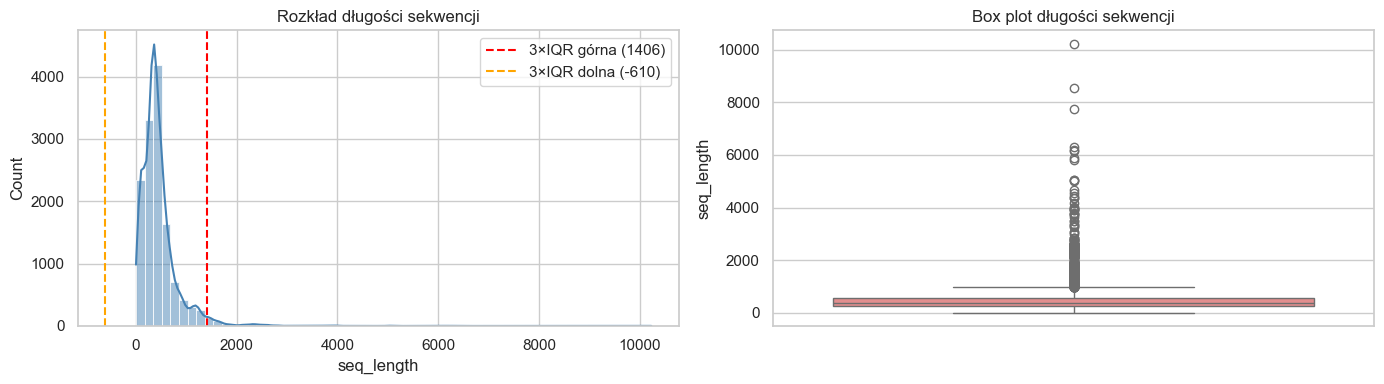

In [35]:
Q1 = data['seq_length'].quantile(0.25)
Q3 = data['seq_length'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 3 * IQR
upper_bound = Q3 + 3 * IQR

print(f"IQR: {IQR:.0f} | Dolna granica: {lower_bound:.0f} | Górna granica: {upper_bound:.0f}")

outliers = data[(data['seq_length'] < lower_bound) | (data['seq_length'] > upper_bound)]
print(f"Wartości odstające (3×IQR): {len(outliers)} białek")

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(data['seq_length'], bins=60, kde=True, ax=axes[0], color='steelblue')
axes[0].axvline(upper_bound, color='red', linestyle='--', label=f'3×IQR górna ({upper_bound:.0f})')
axes[0].axvline(lower_bound, color='orange', linestyle='--', label=f'3×IQR dolna ({lower_bound:.0f})')
axes[0].set_title('Rozkład długości sekwencji')
axes[0].legend()

sns.boxplot(y=data['seq_length'], ax=axes[1], color='lightcoral')
axes[1].set_title('Box plot długości sekwencji')
plt.tight_layout()
plt.show()

In [10]:
print(f"Ostateczny rozmiar po czyszczeniu: {data.shape}")

Ostateczny rozmiar po czyszczeniu: (13515, 6)


---
# 2. Analiza Balansu Klas (Multi-Label)

> **Uwaga:** W klasyfikacji wieloetykietowej (multi-label) nie możemy oceniać balansu klasycznie (liczba próbek na klasę), ponieważ:
> - Każde białko może mieć **wiele** funkcji GO jednocześnie.
> - Mierzymy balans przez:
>   1. **Częstość etykiet** – ile białek ma daną funkcję GO
>   3. **Imbalance Ratio (IR)** – stosunek negatywnych do pozytywnych próbek na etykietę
>   4. **Współwystępowanie** – co-occurrence matrix dla najczęstszych etykiet

In [ ]:
data['label_list'] = data['labels'].str.split(';')
data['label_list'] = data['label_list'].apply(lambda x: [l.strip() for l in x if l.strip()])

# Wszystkie etykiety
all_labels = [lbl for lbls in data['label_list'] for lbl in lbls]
label_counts = pd.Series(all_labels).value_counts()

n_unique_labels = len(label_counts)
n_samples = len(data)
print(f"Liczba białek: {n_samples}")
print(f"Unikalne etykiety GO: {n_unique_labels}")

Liczba białek: 13515
Unikalne etykiety GO: 20


## 2.1 Rozkład częstości etykiet

C:\Users\posze\AppData\Local\Temp\ipykernel_5712\725796752.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_labels.index, y=top_labels.values, palette='viridis', ax=ax)


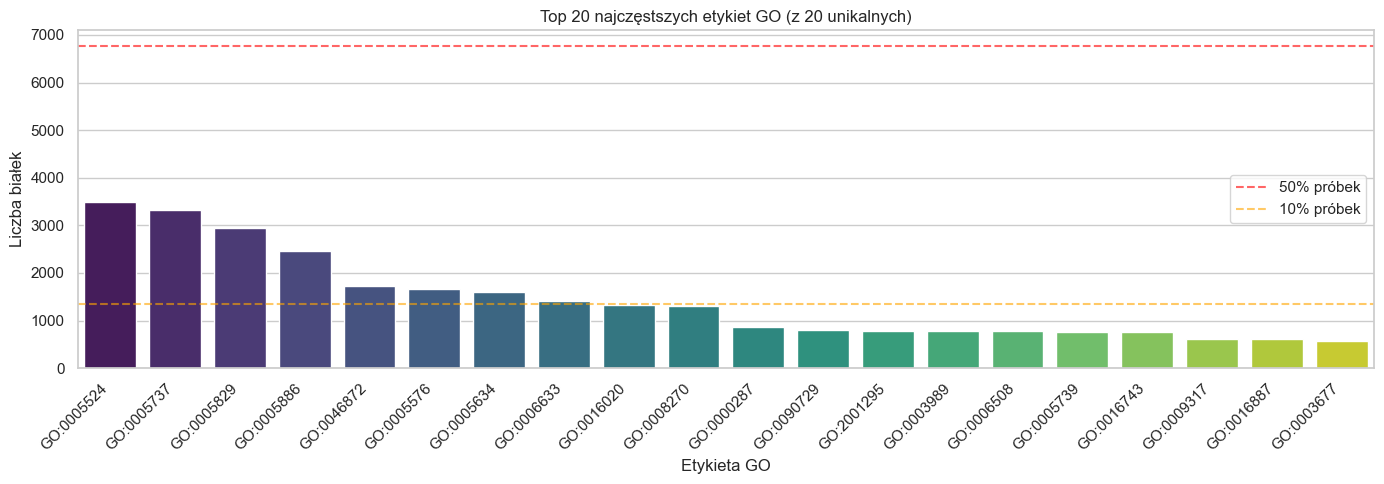

In [32]:
TOP_N = 20
top_labels = label_counts.head(TOP_N)

fig, ax = plt.subplots(figsize=(14, 5))
sns.barplot(x=top_labels.index, y=top_labels.values, palette='viridis', ax=ax)
ax.set_title(f'Top {TOP_N} najczęstszych etykiet GO (z {n_unique_labels} unikalnych)')
ax.set_xlabel('Etykieta GO')
ax.set_ylabel('Liczba białek')
ax.axhline(n_samples * 0.5, color='red', linestyle='--', alpha=0.6, label='50% próbek')
ax.axhline(n_samples * 0.1, color='orange', linestyle='--', alpha=0.6, label='10% próbek')
plt.xticks(rotation=45, ha='right')
ax.legend()
plt.tight_layout()
plt.show()

## 2.2 Imbalance Ratio (IR) per etykieta

$IR_i = \frac{N_{\text{neg}, i}}{N_{\text{pos}, i}}$ — im wyższy, tym bardziej niezbalansowana etykieta.

In [48]:
ir = (n_samples - label_counts) / label_counts  # IR per label

print(f"Mediana IR (wszystkie etykiety): {ir.median():.1f}")
print(f"Maksymalny IR: {ir.max():.1f}  ({ir.idxmax()})")
print(f"Minimalny IR: {ir.min():.2f}  ({ir.idxmin()})")
print(f"Etykiety z IR > 100 (silna nierównowaga): {(ir > 100).sum()}")
print(f"Etykiety z IR > 10  (umiarkowana): {(ir > 10).sum()}")
print(f"Etykiety z IR <= 10 (akceptowalne): {(ir <= 10).sum()}")

Mediana IR (wszystkie etykiety): 11.9
Maksymalny IR: 22.4  (GO:0003677)
Minimalny IR: 2.86  (GO:0005524)
Etykiety z IR > 100 (silna nierównowaga): 0
Etykiety z IR > 10  (umiarkowana): 10
Etykiety z IR <= 10 (akceptowalne): 10


## 2.4 Macierz współwystępowania etykiet (top 15)

c:\Users\posze\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\preprocessing\_label.py:1007: UserWarning: unknown class(es) ['GO:0003677', 'GO:0005739', 'GO:0009317', 'GO:0016743', 'GO:0016887'] will be ignored
  warnings.warn(


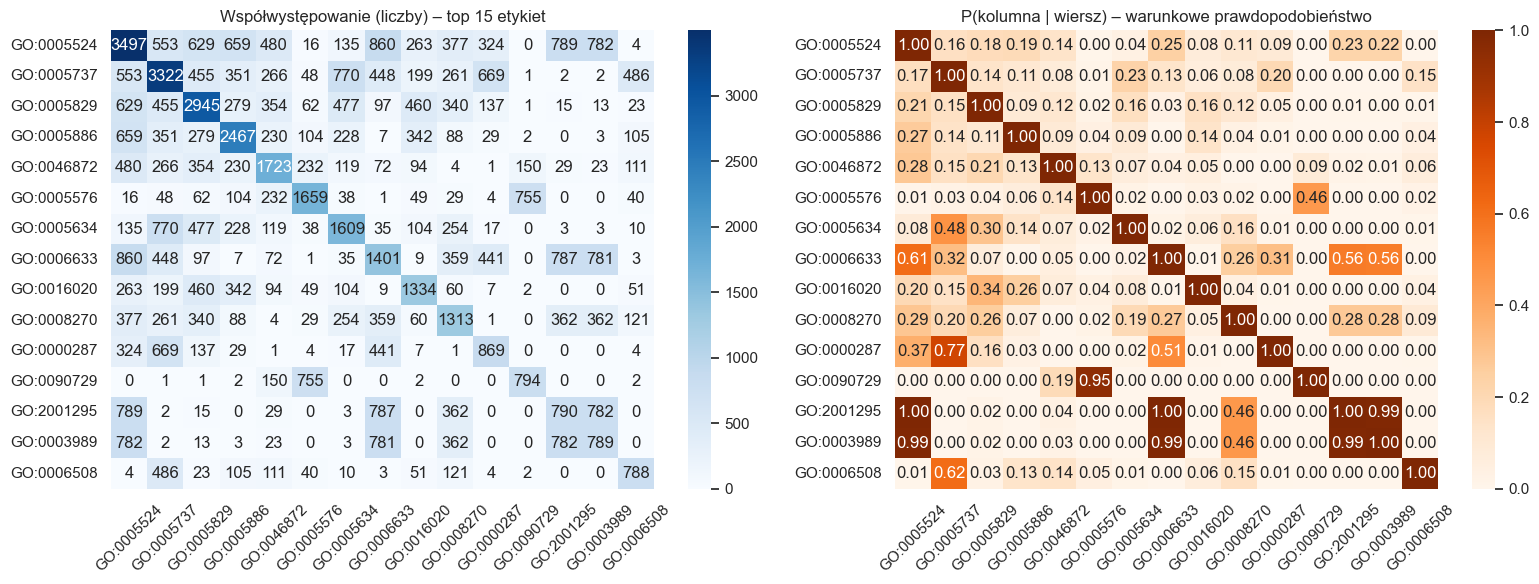

In [38]:
TOP_CO = 15
top_co_labels = label_counts.head(TOP_CO).index.tolist()

mlb_top = MultiLabelBinarizer(classes=top_co_labels)
label_matrix_top = mlb_top.fit_transform(data['label_list'])  # (N, TOP_CO)

co_occurrence = label_matrix_top.T @ label_matrix_top  # (TOP_CO, TOP_CO)
co_df = pd.DataFrame(co_occurrence, index=top_co_labels, columns=top_co_labels)

# Normalizuj do prawdopodobieństwa warunkowego P(j | i)
diag = np.diag(co_occurrence).astype(float)
co_norm = co_occurrence / diag[:, None]  # P(j | i) = co(i,j) / count(i)
co_norm_df = pd.DataFrame(co_norm, index=top_co_labels, columns=top_co_labels)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.heatmap(co_df, annot=True, fmt='d', cmap='Blues', ax=axes[0], cbar=True)
axes[0].set_title(f'Współwystępowanie (liczby) – top {TOP_CO} etykiet')
axes[0].tick_params(axis='x', rotation=45)

sns.heatmap(co_norm_df, annot=True, fmt='.2f', cmap='Oranges', ax=axes[1], cbar=True, vmin=0, vmax=1)
axes[1].set_title(f'P(kolumna | wiersz) – warunkowe prawdopodobieństwo')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

## 2.5 Balans i WeightedRandomSampler
1. **WeightedRandomSampler** – waga próbki = im częściej próbka występuje tym mniejsza waga.

$$w_i = \frac{1}{\sum_{j \in \text{labels}(i)} \text{freq}(j)}$$

Wyższa waga → białka z rzadkimi funkcjami GO są próbkowane częściej.

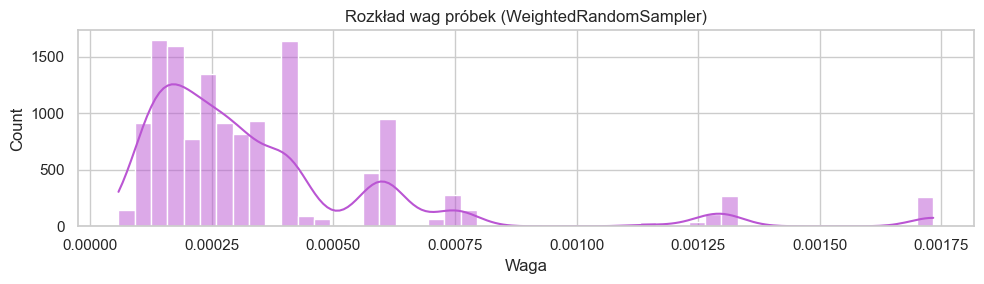

In [39]:
# Obliczanie wag dla WeightedRandomSampler
label_freq = label_counts.to_dict()

def compute_sample_weight(label_list: list) -> float:
    """Waga = 1 / suma_częstości_etykiet_próbki."""
    freq_sum = sum(label_freq.get(lbl, 1) for lbl in label_list)
    return 1.0 / max(freq_sum, 1)

data['sample_weight'] = data['label_list'].apply(compute_sample_weight)

fig, ax = plt.subplots(figsize=(10, 3))
sns.histplot(data['sample_weight'], bins=50, kde=True, ax=ax, color='mediumorchid')
ax.set_title('Rozkład wag próbek (WeightedRandomSampler)')
ax.set_xlabel('Waga')
plt.tight_layout()
plt.show()

---
# 3. Podział Train / Validation / Test

In [51]:
# Stratyfikowany podział względem liczby etykiet
indices = np.arange(len(data))

train_val_idx, test_idx = train_test_split(
    indices, test_size=0.10
)
train_idx, val_idx = train_test_split(
    train_val_idx, test_size=0.10 / 0.90
)

print(f"Train: {len(train_idx):>6,} ({len(train_idx)/len(data)*100:.1f}%)")
print(f"Validation: {len(val_idx):>6,} ({len(val_idx)/len(data)*100:.1f}%)")
print(f"Test: {len(test_idx):>6,} ({len(test_idx)/len(data)*100:.1f}%)")

train_data = data.iloc[train_idx].reset_index(drop=True)
val_data = data.iloc[val_idx].reset_index(drop=True)
test_data = data.iloc[test_idx].reset_index(drop=True)

Train: 10,811 (80.0%)
Validation:  1,352 (10.0%)
Test:  1,352 (10.0%)


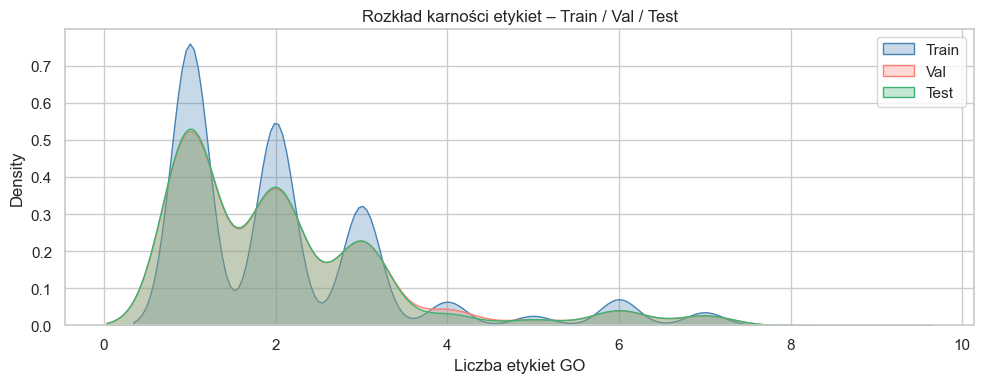

In [42]:
# rozkład karności w train/val/test
fig, ax = plt.subplots(figsize=(10, 4))
for subset, label, color in [(train_data, 'Train', 'steelblue'),
                               (val_data,   'Val',   'salmon'),
                               (test_data,  'Test',  'mediumseagreen')]:
    sns.kdeplot(subset['n_labels'], ax=ax, label=label, color=color, fill=True, alpha=0.3)
ax.set_title('Rozkład karności etykiet – Train / Val / Test')
ax.set_xlabel('Liczba etykiet GO')
ax.legend()
plt.tight_layout()
plt.show()

---
# 4. Ekstrakcja Cech

In [43]:
extractor_train = FeatureExtractor(train_data.to_dict(orient='records'))
features_train = extractor_train.extract_features()  # (N_train, 425)

extractor_val  = FeatureExtractor(val_data.to_dict(orient='records'))
features_val   = extractor_val.extract_features()

extractor_test = FeatureExtractor(test_data.to_dict(orient='records'))
features_test  = extractor_test.extract_features()

feature_names = FeatureExtractor.feature_names()  # 20 + 400 + 5 = 425
print(f"Train shape: {features_train.shape}")
print(f"Val shape:   {features_val.shape}")
print(f"Test shape:  {features_test.shape}")
print(f"Cechy: {len(feature_names)} ({', '.join(feature_names[:3])}, ..., {', '.join(feature_names[-5:])})")

Train shape: (10811, 425)
Val shape:   (1352, 425)
Test shape:  (1352, 425)
Cechy: 425 (freq_A, freq_C, freq_D, ..., avg_aa_mass, charge, hydrophobicity, aromaticity, log_length)


---
# 5. EDA

Wyłącznie na zbiorze treningowym ( zapobiega wycieku danych )

## 5.1 Cechy globalne – histogramy

5 cech globalnych: `avg_aa_mass`, `charge`, `hydrophobicity`, `aromaticity`, `log_length`

In [44]:
GLOBAL_NAMES = ['avg_aa_mass', 'charge', 'hydrophobicity', 'aromaticity', 'log_length']
global_train = features_train[:, -5:]
df_global = pd.DataFrame(global_train, columns=GLOBAL_NAMES)

df_global.describe().round(4)

,avg_aa_mass,charge,hydrophobicity,aromaticity,log_length
count,10811.0000,10811.0000,10811.0000,10811.0000,10811.0000
mean,128.9278,0.0115,0.4123,0.0830,5.8429
std,3.2587,0.0496,0.0570,0.0278,0.8115
min,95.4046,-0.3333,0.0667,0.0000,1.7918
25%,127.0304,-0.0050,0.3908,0.0652,5.5413
50%,129.0563,0.0135,0.4169,0.0812,5.9322
75%,130.9379,0.0329,0.4399,0.0980,6.2971
max,151.0667,0.4000,0.7273,0.4000,9.2329


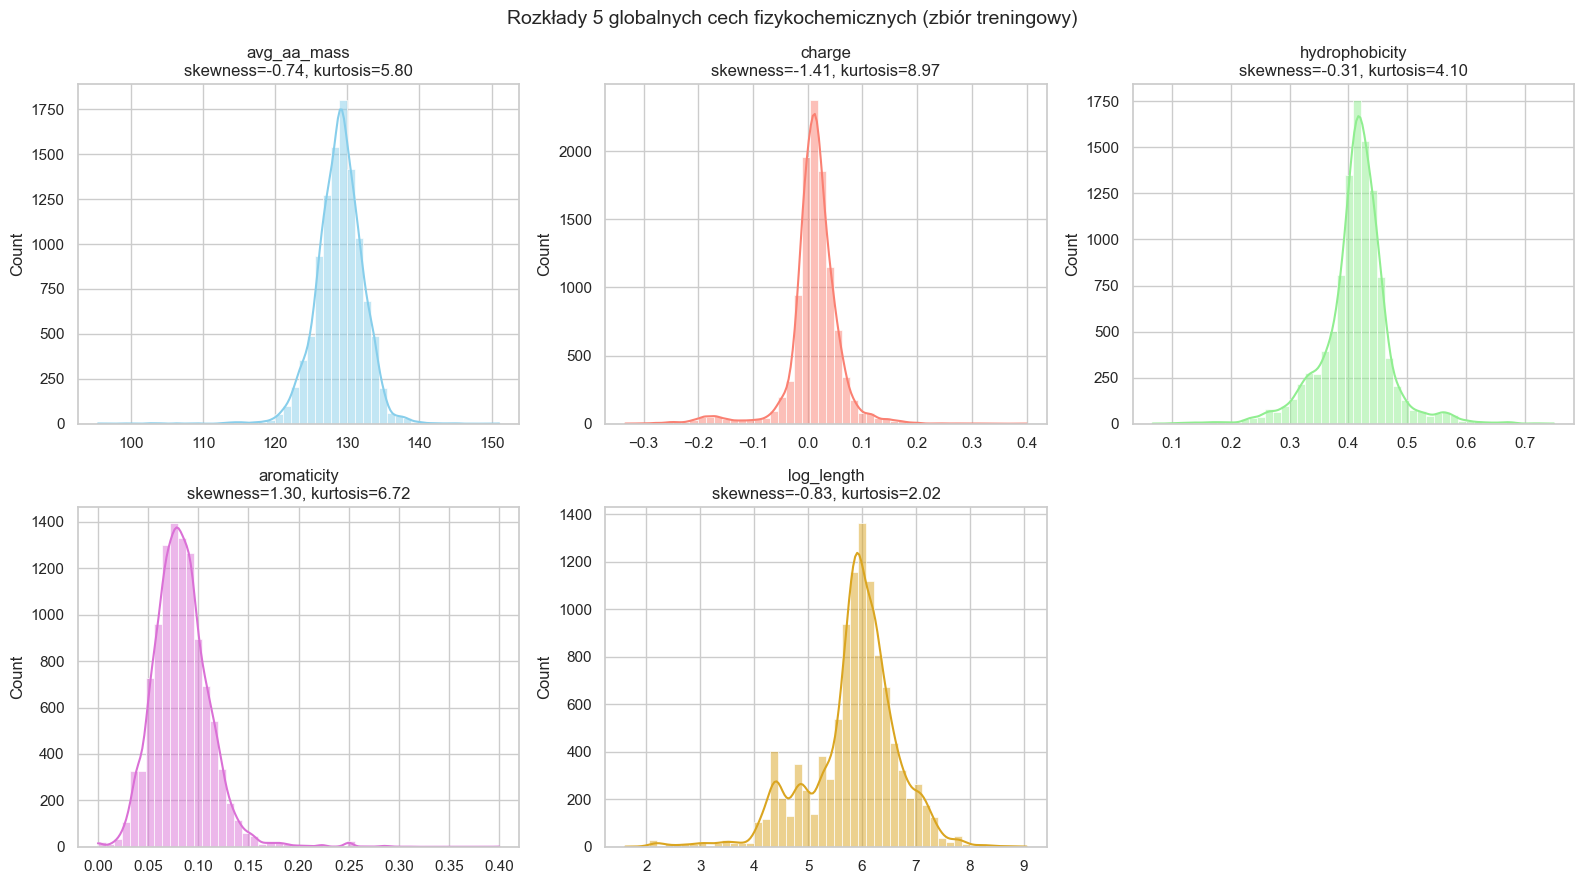

In [22]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()
fig.suptitle('Rozkłady 5 globalnych cech fizykochemicznych (zbiór treningowy)', fontsize=14)

colors = ['skyblue', 'salmon', 'lightgreen', 'orchid', 'goldenrod']

for i, (name, color) in enumerate(zip(GLOBAL_NAMES, colors)):
    skew = stats.skew(df_global[name])
    kurt = stats.kurtosis(df_global[name])
    sns.histplot(df_global[name], bins=50, kde=True, ax=axes[i], color=color)
    axes[i].set_title(f'{name}\nskewness={skew:.2f}, kurtosis={kurt:.2f}')
    axes[i].set_xlabel('')

axes[-1].set_visible(False)
plt.tight_layout()
plt.show()

## 5.2 Pair plot cech globalnych

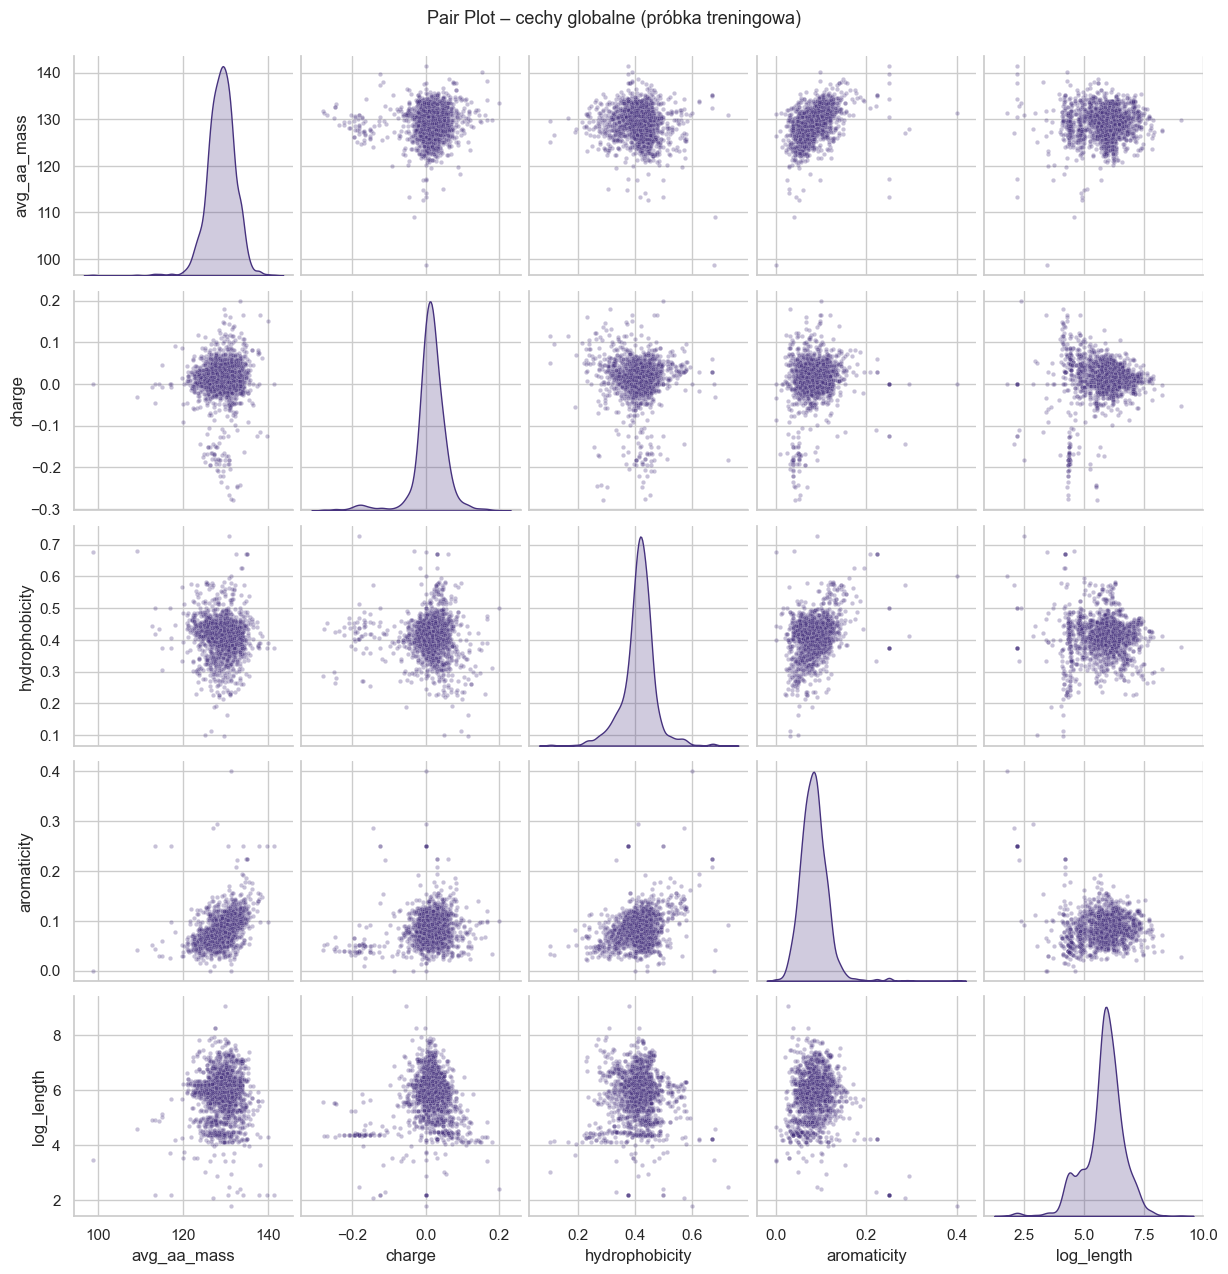

In [23]:
# Subsample jeśli zbyt dużo próbek
sample_size = min(2000, len(df_global))
df_sample = df_global.sample(sample_size, random_state=42)

pair_grid = sns.pairplot(df_sample, diag_kind='kde', plot_kws={'alpha': 0.3, 's': 10},
                          diag_kws={'fill': True})
pair_grid.fig.suptitle('Pair Plot – cechy globalne (próbka treningowa)', y=1.02, fontsize=13)
plt.show()

## 5.3 Analiza korelacji cech globalnych

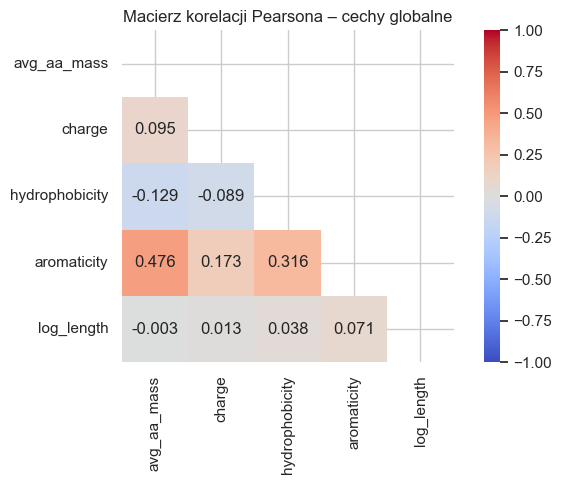

Brak par z |r| > 0.70 wśród cech globalnych.


In [46]:
corr_global = df_global.corr()

fig, ax = plt.subplots(figsize=(7, 5))
mask = np.triu(np.ones_like(corr_global, dtype=bool))
sns.heatmap(corr_global, annot=True, fmt='.3f', cmap='coolwarm',
            vmin=-1, vmax=1, mask=mask, ax=ax, square=True)
ax.set_title('Macierz korelacji Pearsona – cechy globalne')
plt.tight_layout()
plt.show()

# Pary o wysokiej korelacji (|r| > 0.7)
high_corr = []
for i in range(len(corr_global.columns)):
    for j in range(i+1, len(corr_global.columns)):
        r = corr_global.iloc[i, j]
        if abs(r) > 0.7:
            high_corr.append((corr_global.columns[i], corr_global.columns[j], r))

if high_corr:
    print("Pary z |r| > 0.70 (potencjalna multikolinearność):")
    for a, b, r in high_corr:
        print(f"{a} <-> {b}: r = {r:.3f}")
else:
    print("Brak par z |r| > 0.70 wśród cech globalnych.")

## 5.4 Variance Inflation Factor (VIF)

VIF > 10 sygnalizuje silną multikolinearność – cecha kandyduje do usunięcia.

C:\Users\posze\AppData\Local\Temp\ipykernel_5712\3525619744.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  bars = sns.barplot(data=vif_data, x='feature', y='VIF', palette='coolwarm', ax=ax)


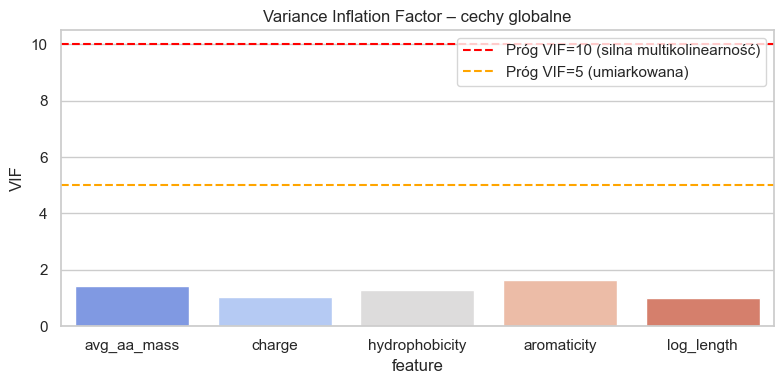

       feature      VIF
   avg_aa_mass 1.431810
        charge 1.050709
hydrophobicity 1.271841
   aromaticity 1.634590
    log_length 1.001141

Brak cech z VIF > 10.


In [ ]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

X_vif = df_global.copy()
X_vif.insert(0, 'const', 1.0)

vif_data = pd.DataFrame({
    'feature': df_global.columns,
    'VIF': [variance_inflation_factor(X_vif.values, i+1) for i in range(len(df_global.columns))]
})

fig, ax = plt.subplots(figsize=(8, 4))
bars = sns.barplot(data=vif_data, x='feature', y='VIF', palette='coolwarm', ax=ax)
ax.axhline(10, color='red', linestyle='--', label='Próg VIF=10 (silna multikolinearność)')
ax.axhline(5,  color='orange', linestyle='--', label='Próg VIF=5 (umiarkowana)')
ax.set_title('Variance Inflation Factor – cechy globalne')
ax.legend()
plt.tight_layout()
plt.show()

print(vif_data.to_string(index=False))
high_vif = vif_data[vif_data['VIF'] > 10]['feature'].tolist()
if high_vif:
    print(f"\nCechy z VIF > 10 (kandydaci do usunięcia): {high_vif}")
else:
    print("\nBrak cech z VIF > 10.")

---
# 6. Skalowanie Cech

Decyzja: `StandardScaler` vs `RobustScaler`.

| Sytuacja | Skaler |
|---|---|
| Rozkłady zbliżone do normalnych, mało outlierów | `StandardScaler` |
| Wyraźne asymetrie lub dużo outlierów | `RobustStandardScaler` |

Sprawdzamy dla cech globalnych (najbardziej interpretowalnych).

In [54]:
skewness = df_global.skew().abs()
print("Asymetria (|skewness|) cech globalnych:")
print(skewness.round(3).to_string())

n_high_skew = (skewness > 1.0).sum()
print(f"\nCechy z |skewness| > 1.0: {n_high_skew} z {len(skewness)}")

if n_high_skew > len(GLOBAL_NAMES) // 2:
    scaler_choice = 'RobustStandardScaler'
    print("→ Zalecany: RobustStandardScaler (asymetria / outliers)")
else:
    scaler_choice = 'StandardScaler'
    print("→ Zalecany: StandardScaler (rozkłady zbliżone do normalnych)")

Asymetria (|skewness|) cech globalnych:
avg_aa_mass       0.671
charge            1.392
hydrophobicity    0.376
aromaticity       1.150
log_length        0.738

Cechy z |skewness| > 1.0: 2 z 5
→ Zalecany: StandardScaler (rozkłady zbliżone do normalnych)


In [56]:
# Dopasowanie TYLKO na zbiorze treningowym → transformacja train/val/test
if scaler_choice == 'RobustStandardScaler':
    scaler = RobustScaler()
else:
    scaler = StandardScaler()

features_train_scaled = scaler.fit_transform(features_train)
features_val_scaled = scaler.transform(features_val)
features_test_scaled = scaler.transform(features_test)

print(f"Użyty skaler: {scaler_choice}")
print(f"Train po skalowaniu – mean: {features_train_scaled.mean():.4f}, std: {features_train_scaled.std():.4f}")
print(f"Val po skalowaniu   – mean: {features_val_scaled.mean():.4f}, std: {features_val_scaled.std():.4f}")

Użyty skaler: StandardScaler
Train po skalowaniu – mean: 0.0000, std: 1.0000
Val po skalowaniu   – mean: 0.0012, std: 1.0338


---
# 7. Zapis Wyników

In [60]:
import os
os.makedirs('../data', exist_ok=True)

col_names = feature_names

pd.DataFrame(features_train_scaled, columns=col_names).to_csv(
    '../data/mini_cafa_features_train.csv', index=False)

pd.DataFrame(features_val_scaled, columns=col_names).to_csv(
    '../data/mini_cafa_features_val.csv', index=False)

pd.DataFrame(features_test_scaled, columns=col_names).to_csv(
    '../data/mini_cafa_features_test.csv', index=False)

# Zapisz wagi dla WeightedRandomSampler (tylko train)
weights_train = train_data['sample_weight'].values
np.save('../data/sample_weights_train.npy', weights_train)

print("Zapisano:")
print(f"mini_cafa_features_train.csv  → {features_train_scaled.shape}")
print(f"mini_cafa_features_val.csv    → {features_val_scaled.shape}")
print(f"mini_cafa_features_test.csv   → {features_test_scaled.shape}")
print(f"sample_weights_train.npy      → {weights_train.shape}")

Zapisano:
mini_cafa_features_train.csv  → (10811, 425)
mini_cafa_features_val.csv    → (1352, 425)
mini_cafa_features_test.csv   → (1352, 425)
sample_weights_train.npy      → (10811,)
